# BioASQ 12b — Yes/No Question Answering
## Data Acquisition and Preprocessing

**Notebook purpose:** acquire a publicly accessible, processed copy of BioASQ 12b question data, inspect its structure, isolate yes/no questions, extract candidate labels and evidence snippets, run quality checks, create reproducible data splits, and export the resulting files.

**Selected source:** [mattmorgis/bioasq-12b-rag on Hugging Face](https://huggingface.co/datasets/mattmorgis/bioasq-12b-rag)

**Dataset configuration:** `question-answer-passages`

> **Data provenance note:** This is a third-party processed derivative of BioASQ 12b, not a verified byte-for-byte copy of the original BioASQ participant download. The source's `answer` field contains natural-language ideal answers. This notebook derives a candidate YES/NO label only when the answer begins with `Yes` or `No`. These labels must be manually audited before model training. The source's separate `eval` split should not be described as the official BioASQ golden test set unless that equivalence is independently verified.

### Workflow
1. Install dependencies and configure folders.
2. Download and inspect the Hugging Face dataset.
3. Save the source question splits locally.
4. Filter yes/no questions and extract candidate labels and evidence.
5. Review data quality and create a manual audit sample.
6. Split the development data into train, validation, and internal test sets.
7. Export the processed files, manifest, documentation, and ZIP backup.

**How to use this notebook:** Upload it to Google Colab and use **Runtime → Run all**. The notebook downloads the source data, preprocesses it, exports the result files, and creates a ZIP backup at the end. Do not run an additional `preprocess.py` command in Colab.


## 1. Install dependencies

Run this cell first. It installs the Hugging Face `datasets` library and the packages used for data splitting and visualization. Google Colab already includes pandas and NumPy, so this notebook does not force-upgrade them.

**Important:** This notebook already performs the complete acquisition and preprocessing workflow. You do not need to run `src/preprocess.py` separately when working in Google Colab. That standalone script is only for a separate local workflow.


In [1]:
# Install only the libraries needed for this notebook.
# Do not force-upgrade pandas or NumPy in Google Colab.
%pip -q install datasets scikit-learn matplotlib


## 2. Import libraries

In [2]:
import json
import re
import shutil
from collections import Counter
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import load_dataset
from sklearn.model_selection import train_test_split

print("Imports completed.")

Imports completed.


## 3. Configure the project

The notebook stores files under `/content/BioASQ-YesNo-QA`. Colab runtimes are temporary, so the ZIP backup created near the end should be downloaded or copied to persistent storage.

In [3]:
DATASET_ID = "mattmorgis/bioasq-12b-rag"
DATASET_CONFIG = "question-answer-passages"
RANDOM_SEED = 42

PROJECT_DIR = Path("/content/BioASQ-YesNo-QA")
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

np.random.seed(RANDOM_SEED)

print("Project directory:", PROJECT_DIR)
print("Raw data directory:", RAW_DIR)
print("Processed data directory:", PROCESSED_DIR)

Project directory: /content/BioASQ-YesNo-QA
Raw data directory: /content/BioASQ-YesNo-QA/data/raw
Processed data directory: /content/BioASQ-YesNo-QA/data/processed


## 4. Download the dataset from Hugging Face

The dataset card documents the `question-answer-passages` configuration and the `dev` and `eval` question splits. This cell downloads that configuration.

Dataset page: https://huggingface.co/datasets/mattmorgis/bioasq-12b-rag

In [4]:
dataset = load_dataset(DATASET_ID, DATASET_CONFIG)

print(dataset)
print("Available splits:", list(dataset.keys()))

for split_name in dataset.keys():
    print(f"{split_name}: {len(dataset[split_name]):,} records")

README.md:   0%|          | 0.00/4.37k [00:00<?, ?B/s]

data/dev.jsonl: reconstructing file:   0%|          |  0.00B / 26.0MB            

data/dev.jsonl: downloading bytes:           |  0.00B            

data/eval.jsonl: reconstructing file:   0%|          |  0.00B / 4.44MB            

data/eval.jsonl: downloading bytes:           |  0.00B            

Generating dev split:   0%|          | 0/5049 [00:00<?, ? examples/s]

Generating eval split:   0%|          | 0/340 [00:00<?, ? examples/s]

DatasetDict({
    dev: Dataset({
        features: ['question_id', 'question', 'answer', 'relevant_passage_ids', 'type', 'snippets'],
        num_rows: 5049
    })
    eval: Dataset({
        features: ['question_id', 'question', 'answer', 'relevant_passage_ids', 'type', 'snippets'],
        num_rows: 340
    })
})
Available splits: ['dev', 'eval']
dev: 5,049 records
eval: 340 records


## 5. Check the dataset structure

Before preprocessing, verify that the downloaded dataset contains the fields expected by this notebook. Also inspect one sample record so the actual data structure is visible in the notebook output.

In [5]:
if "dev" not in dataset:
    raise ValueError(
        f"Expected a 'dev' split. Available splits: {list(dataset.keys())}"
    )

if "eval" in dataset:
    EVAL_SPLIT = "eval"
elif "test" in dataset:
    EVAL_SPLIT = "test"
else:
    raise ValueError(
        f"Expected an 'eval' or 'test' split. Available splits: {list(dataset.keys())}"
    )

DEV_SPLIT = "dev"

required_columns = {
    "question_id", "question", "answer", "type", "snippets"
}
actual_columns = set(dataset[DEV_SPLIT].column_names)
missing_columns = required_columns - actual_columns

if missing_columns:
    raise ValueError(f"Missing expected columns: {sorted(missing_columns)}")

print("Development split columns:")
print(dataset[DEV_SPLIT].column_names)

print("\nExample source record:")
print(json.dumps(dataset[DEV_SPLIT][0], indent=2, ensure_ascii=False, default=str))

Development split columns:
['question_id', 'question', 'answer', 'relevant_passage_ids', 'type', 'snippets']

Example source record:
{
  "question_id": "55031181e9bde69634000014",
  "question": "Is Hirschsprung disease a mendelian or a multifactorial disorder?",
  "answer": "Coding sequence mutations in RET, GDNF, EDNRB, EDN3, and SOX10 are involved in the development of Hirschsprung disease. The majority of these genes was shown to be related to Mendelian syndromic forms of Hirschsprung's disease, whereas the non-Mendelian inheritance of sporadic non-syndromic Hirschsprung disease proved to be complex; involvement of multiple loci was demonstrated in a multiplicative model.",
  "relevant_passage_ids": [
    "15858239",
    "20598273",
    "15829955",
    "6650562",
    "12239580",
    "21995290",
    "15617541",
    "23001136",
    "8896569"
  ],
  "type": "summary",
  "snippets": [
    {
      "offsetInBeginSection": 131,
      "offsetInEndSection": 358,
      "text": "Hirschsprung d

## 6. Count the question types

BioASQ includes several question types. This project focuses only on `yesno` questions. Record the type distribution before filtering so the selection process is transparent.

In [6]:
question_type_counts = {}

for split_name in [DEV_SPLIT, EVAL_SPLIT]:
    counts = Counter(
        str(record.get("type", "unknown")).strip().lower()
        for record in dataset[split_name]
    )
    question_type_counts[split_name] = dict(counts)

    print(f"\n{split_name.upper()} question types")
    for question_type, count in sorted(counts.items()):
        print(f"{question_type}: {count:,}")


DEV question types
factoid: 1,515
list: 967
summary: 1,210
yesno: 1,357

EVAL question types
factoid: 85
list: 80
summary: 73
yesno: 102


## 7. Save the original question splits

Save the downloaded question records as JSON Lines (`.jsonl`) files. These are raw local copies for reproducibility. Do not commit the raw dataset files to a public GitHub repository unless the applicable dataset terms and your project requirements explicitly allow it.

In [7]:
def save_jsonl(records, output_path):
    with open(output_path, "w", encoding="utf-8") as file:
        for record in records:
            file.write(
                json.dumps(record, ensure_ascii=False, default=str) + "\n"
            )

save_jsonl(dataset[DEV_SPLIT], RAW_DIR / "bioasq12b_dev.jsonl")
save_jsonl(dataset[EVAL_SPLIT], RAW_DIR / f"bioasq12b_{EVAL_SPLIT}.jsonl")

print("Saved raw question splits:")
for path in sorted(RAW_DIR.glob("*.jsonl")):
    print(f"- {path.name}: {path.stat().st_size / (1024 * 1024):.2f} MB")

Saved raw question splits:
- bioasq12b_dev.jsonl: 24.73 MB
- bioasq12b_eval.jsonl: 4.22 MB


## 8. Filter yes/no questions

Retain records whose `type` field is exactly `yesno` (case-insensitive). We keep the source `dev` and `eval` splits separate throughout preprocessing.

In [8]:
def is_yesno(record):
    return str(record.get("type", "")).strip().lower() == "yesno"

yesno_dev = dataset[DEV_SPLIT].filter(is_yesno)
yesno_eval = dataset[EVAL_SPLIT].filter(is_yesno)

print(f"Yes/no questions in dev: {len(yesno_dev):,}")
print(f"Yes/no questions in {EVAL_SPLIT}: {len(yesno_eval):,}")

Filter:   0%|          | 0/5049 [00:00<?, ? examples/s]

Filter:   0%|          | 0/340 [00:00<?, ? examples/s]

Yes/no questions in dev: 1,357
Yes/no questions in eval: 102


## 9. Define label and evidence extraction functions

### Candidate label extraction

The `answer` field is natural-language text, not a structured binary label column. This function accepts a label only when the answer starts with `Yes` or `No`. It does not search for those words elsewhere in the answer, because doing so could assign an incorrect label.

### Evidence extraction

The source `snippets` field contains snippet objects. This function extracts each object's `text` value. The first 1, 3, and 5 snippets are retained in source order for later experiments. The dataset card does not establish that this order represents a relevance ranking.

In [9]:
def extract_candidate_label(answer):
    """Return YES or NO only when the answer begins with that word."""
    if not isinstance(answer, str):
        return None

    match = re.match(r"^\s*(yes|no)\b", answer, flags=re.IGNORECASE)
    if match:
        return match.group(1).upper()
    return None


def extract_snippet_texts(snippets):
    """Extract non-empty snippet text from a list of snippet objects/strings."""
    if not isinstance(snippets, (list, tuple)):
        return []

    extracted = []
    for snippet in snippets:
        if isinstance(snippet, dict):
            text = snippet.get("text", "")
        elif isinstance(snippet, str):
            text = snippet
        else:
            text = ""

        if isinstance(text, str) and text.strip():
            extracted.append(text.strip())

    return extracted


# Quick function checks
assert extract_candidate_label("Yes, this is supported.") == "YES"
assert extract_candidate_label("No, it is not supported.") == "NO"
assert extract_candidate_label("The answer is yes.") is None

print("Label and evidence extraction functions are ready.")

Label and evidence extraction functions are ready.


## 10. Inspect candidate labels before building the processed dataset

Display examples of yes/no answers and their extracted candidate labels. This is an early check that the answer prefix convention works with the actual downloaded records.

In [10]:
preview_rows = []
for record in list(yesno_dev)[:15]:
    answer = record.get("answer", "")
    preview_rows.append({
        "question_id": record.get("question_id"),
        "question": record.get("question"),
        "answer_prefix": answer[:250] if isinstance(answer, str) else answer,
        "candidate_label": extract_candidate_label(answer),
    })

pd.DataFrame(preview_rows)

,question_id,question,answer_prefix,candidate_label
0,54e25eaaae9738404b000017,Is the protein Papilin secreted?,"Yes, papilin is a secreted protein",YES
1,535d292a9a4572de6f000003,Are long non coding RNAs spliced?,Long non coding RNAs appear to be spliced thro...,None
2,55262a9787ecba3764000009,Is RANKL secreted from the cells?,Receptor activator of nuclear factor κB ligand...,None
3,51406e6223fec90375000009,Does metformin interfere thyroxine absorption?,No. There are not reported data indicating tha...,NO
4,52bf1db603868f1b06000011,Has Denosumab (Prolia) been approved by FDA?,"Yes, Denosumab was approved by the FDA in 2010.",YES
5,5313b049e3eabad021000013,Is the monoclonal antibody Trastuzumab (Hercep...,"Although is still controversial, Trastuzumab (...",None
6,517395b98ed59a060a00001a,Are transcription and splicing connected?,Yes. There is strong evidence that splicing an...,YES
7,54db1d580f63c58e6e000005,Is Alu hypomethylation associated with breast ...,"Yes, Alu elements were found to be hypomethyla...",YES
8,51593dc8d24251bc05000099,Proteomic analyses need prior knowledge of the...,"Yes, the complete genome sequence of Arthrobac...",YES
9,56bf365eef6e39474100000e,Do mutations of AKT1 occur in meningiomas?,"Yes, AKT1 mutation occurs in meningiomas.",YES


## 11. Build the processed dataset and rejection log

A record is retained only if it has:
- a question ID;
- non-empty question text;
- a candidate YES/NO label extracted from the beginning of the answer; and
- at least one non-empty evidence snippet.

Records that do not meet these checks are written to a rejection log with a reason. Duplicate question IDs within a source split are also logged, keeping the first valid occurrence.

In [11]:
PROCESSED_COLUMNS = [
    "question_id",
    "question",
    "answer_text",
    "label",
    "label_id",
    "evidence_all",
    "evidence_first_1",
    "evidence_first_3",
    "evidence_first_5",
    "num_snippets",
    "relevant_passage_ids",
    "source_split",
]


def prepare_split(records, split_name):
    processed_rows = []
    rejected_rows = []

    for record in records:
        question_id = record.get("question_id")
        question = record.get("question", "")
        answer = record.get("answer", "")
        candidate_label = extract_candidate_label(answer)
        snippets = extract_snippet_texts(record.get("snippets", []))

        reasons = []
        if question_id is None or not str(question_id).strip():
            reasons.append("Missing question_id")
        if not isinstance(question, str) or not question.strip():
            reasons.append("Missing or invalid question")
        if candidate_label is None:
            reasons.append("Answer does not begin with YES or NO")
        if not snippets:
            reasons.append("Missing usable evidence snippets")

        if reasons:
            rejected_rows.append({
                "question_id": question_id,
                "question": question,
                "answer": answer,
                "reason": "; ".join(reasons),
                "source_split": split_name,
            })
            continue

        passage_ids = record.get("relevant_passage_ids", [])
        processed_rows.append({
            "question_id": str(question_id),
            "question": question.strip(),
            "answer_text": answer.strip(),
            "label": candidate_label,
            "label_id": 1 if candidate_label == "YES" else 0,
            "evidence_all": "\n\n".join(snippets),
            "evidence_first_1": "\n\n".join(snippets[:1]),
            "evidence_first_3": "\n\n".join(snippets[:3]),
            "evidence_first_5": "\n\n".join(snippets[:5]),
            "num_snippets": len(snippets),
            "relevant_passage_ids": json.dumps(passage_ids, ensure_ascii=False),
            "source_split": split_name,
        })

    processed_df = pd.DataFrame(processed_rows, columns=PROCESSED_COLUMNS)
    rejected_df = pd.DataFrame(
        rejected_rows,
        columns=["question_id", "question", "answer", "reason", "source_split"]
    )

    if not processed_df.empty:
        duplicate_mask = processed_df["question_id"].duplicated(keep="first")
        duplicate_rows = processed_df.loc[duplicate_mask]

        if not duplicate_rows.empty:
            duplicate_log = pd.DataFrame({
                "question_id": duplicate_rows["question_id"],
                "question": duplicate_rows["question"],
                "answer": duplicate_rows["answer_text"],
                "reason": "Duplicate question_id within source split",
                "source_split": split_name,
            })
            rejected_df = pd.concat([rejected_df, duplicate_log], ignore_index=True)
            processed_df = processed_df.loc[~duplicate_mask].reset_index(drop=True)

    return processed_df, rejected_df


dev_df, dev_rejected = prepare_split(yesno_dev, "dev")
eval_df, eval_rejected = prepare_split(yesno_eval, EVAL_SPLIT)

print("Processed development rows:", len(dev_df))
print("Rejected development rows:", len(dev_rejected))
print(f"Processed {EVAL_SPLIT} rows:", len(eval_df))
print(f"Rejected {EVAL_SPLIT} rows:", len(eval_rejected))

Processed development rows: 914
Rejected development rows: 443
Processed eval rows: 59
Rejected eval rows: 43


## 12. Review the cleaned records and label distribution

The values below are candidate labels extracted from ideal-answer text. They are not guaranteed to be equivalent to the official structured `exact_answer` annotations. Review the manual-audit file in a later step before training.

In [12]:
print("Development label counts:")
display(dev_df["label"].value_counts(dropna=False).rename("count").to_frame())

print("Evaluation label counts:")
display(eval_df["label"].value_counts(dropna=False).rename("count").to_frame())

print("Sample processed records:")
display(dev_df[["question_id", "question", "answer_text", "label", "num_snippets"]].head(10))

Development label counts:


,count
label,
YES,676
NO,238


Evaluation label counts:


,count
label,
YES,38
NO,21


Sample processed records:


,question_id,question,answer_text,label,num_snippets
0,54e25eaaae9738404b000017,Is the protein Papilin secreted?,"Yes, papilin is a secreted protein",YES,8
1,51406e6223fec90375000009,Does metformin interfere thyroxine absorption?,No. There are not reported data indicating tha...,NO,2
2,52bf1db603868f1b06000011,Has Denosumab (Prolia) been approved by FDA?,"Yes, Denosumab was approved by the FDA in 2010.",YES,22
3,517395b98ed59a060a00001a,Are transcription and splicing connected?,Yes. There is strong evidence that splicing an...,YES,17
4,54db1d580f63c58e6e000005,Is Alu hypomethylation associated with breast ...,"Yes, Alu elements were found to be hypomethyla...",YES,7
5,51593dc8d24251bc05000099,Proteomic analyses need prior knowledge of the...,"Yes, the complete genome sequence of Arthrobac...",YES,7
6,56bf365eef6e39474100000e,Do mutations of AKT1 occur in meningiomas?,"Yes, AKT1 mutation occurs in meningiomas.",YES,19
7,5158644cd24251bc0500008e,Does physical activity influence gut hormones?,Yes.,YES,17
8,54f08d4a94afd61504000016,Is irritable bowel syndrome more common in wom...,"Yes, irritable bowel syndrome (IBS) is more co...",YES,25
9,553a8d78f321868558000003,Are ultraconserved elements often transcribed?,"Yes. Especially, a large fraction of non-exon...",YES,23


## 13. Run data-quality checks

Check missing values, duplicate IDs, empty text, invalid labels, and evidence availability. These checks help identify technical problems, but they do not replace manual verification that the extracted label is semantically correct.

In [13]:
def quality_report(name, df):
    print(f"\n--- {name} ---")
    print("Rows:", len(df))

    if df.empty:
        print("No rows available for quality checks.")
        return

    print("\nMissing values:")
    display(df.isna().sum().to_frame("missing_count"))

    print("Duplicate question IDs:", int(df["question_id"].duplicated().sum()))
    print("Empty questions:", int((df["question"].str.strip() == "").sum()))
    print("Empty evidence:", int((df["evidence_all"].str.strip() == "").sum()))
    print("Unexpected labels:", sorted(set(df["label"].dropna()) - {"YES", "NO"}))

quality_report("Processed development data", dev_df)
quality_report(f"Processed {EVAL_SPLIT} data", eval_df)

print("\nRejected development records by reason:")
if not dev_rejected.empty:
    display(dev_rejected["reason"].value_counts().to_frame("count"))
else:
    print("None")

print(f"\nRejected {EVAL_SPLIT} records by reason:")
if not eval_rejected.empty:
    display(eval_rejected["reason"].value_counts().to_frame("count"))
else:
    print("None")


--- Processed development data ---
Rows: 914

Missing values:


,missing_count
question_id,0
question,0
answer_text,0
label,0
label_id,0
evidence_all,0
evidence_first_1,0
evidence_first_3,0
evidence_first_5,0
num_snippets,0


Duplicate question IDs: 0
Empty questions: 0
Empty evidence: 0
Unexpected labels: []

--- Processed eval data ---
Rows: 59

Missing values:


,missing_count
question_id,0
question,0
answer_text,0
label,0
label_id,0
evidence_all,0
evidence_first_1,0
evidence_first_3,0
evidence_first_5,0
num_snippets,0


Duplicate question IDs: 0
Empty questions: 0
Empty evidence: 0
Unexpected labels: []

Rejected development records by reason:


,count
reason,
Answer does not begin with YES or NO,443



Rejected eval records by reason:


,count
reason,
Answer does not begin with YES or NO,43


## 14. Visualize the candidate label distribution

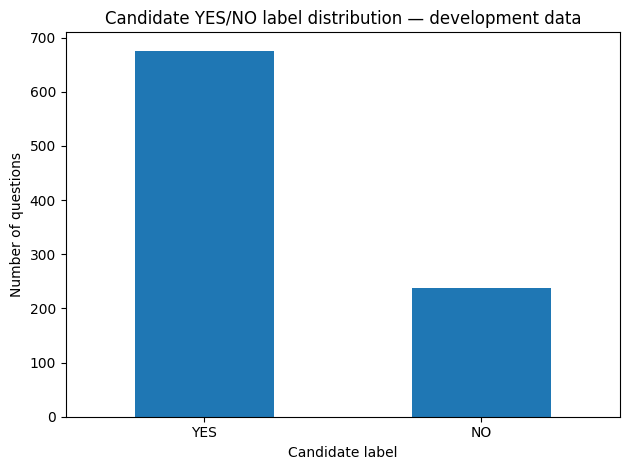

In [14]:
if not dev_df.empty:
    label_counts = dev_df["label"].value_counts().reindex(["YES", "NO"], fill_value=0)
    ax = label_counts.plot(kind="bar", rot=0)
    ax.set_title("Candidate YES/NO label distribution — development data")
    ax.set_xlabel("Candidate label")
    ax.set_ylabel("Number of questions")
    plt.tight_layout()
    plt.show()
else:
    print("No processed development records to plot.")

## 15. Create a manual label-audit sample

Export up to 50 examples for manual review, sampled across both candidate labels where possible. Open `manual_label_audit.csv` after downloading the output ZIP and verify that each answer really supports the assigned YES/NO label and that the evidence is relevant.

**Do not begin model training until this review is complete.** If any labels are wrong, correct them using a documented procedure and keep a record of the changes.

In [15]:
audit_parts = []

if not dev_df.empty:
    for label in ["YES", "NO"]:
        class_df = dev_df[dev_df["label"] == label]
        if not class_df.empty:
            audit_parts.append(
                class_df.sample(
                    n=min(25, len(class_df)),
                    random_state=RANDOM_SEED
                )
            )

audit_df = (
    pd.concat(audit_parts, ignore_index=True)
    if audit_parts
    else pd.DataFrame(columns=dev_df.columns)
)

if not audit_df.empty:
    audit_df = audit_df.sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)

audit_columns = [
    "question_id", "question", "answer_text", "label", "label_id", "evidence_all"
]
audit_df[audit_columns].to_csv(
    PROCESSED_DIR / "manual_label_audit.csv",
    index=False
)

print(f"Manual audit sample created: {len(audit_df)} records")
display(audit_df[audit_columns].head(10))

Manual audit sample created: 50 records


,question_id,question,answer_text,label,label_id,evidence_all
0,550e6688a103b7801600000d,Has the fungus Ashbya gossypii got many nuclei...,"Yes, Ashbya gossypii has a budding yeast-like ...",YES,1,multinucleated Ashbya gossypii cells.\n\nmulti...
1,5e776541835f4e4777000009,Can MVA85A confer immunity against smallpox?,No MVA85A is a candidate tuberculosis vaccine.,NO,0,"We assessed the safety, immunogenicity, and ef..."
2,6026754f1cb411341a0000c8,Should minocycline be used for mild Alzheimer ...,No. Minocycline did not delay the progress of ...,NO,0,Conclusions and Relevance: Minocycline did not...
3,61fa904fc9dfcb9c09000004,Is Erythropoietin effective for neuroprotectio...,No. High-dose erythropoietin treatment adminis...,NO,0,BACKGROUND: High-dose erythropoietin has been ...
4,622dd1433a8413c6530000a5,Is taxilin a cancer marker?,"Yes,\nα-Taxilin, a binding partner of the synt...",YES,1,Αlpha-Taxilin (α-Taxilin) has been found as on...
5,63f9cdb033942b094c000012,Does silencing of SRRM4 promote microexon incl...,"No, silencing of SRRM4 does not promote microe...",NO,0,SRRM4 Expands the Repertoire of Circular RNAs ...
6,532f08dcd6d3ac6a3400002a,Are there any specific antidotes for dabigatran?,No specific antidote currently exists for dabi...,NO,0,"Novel oral anticoagulants (NOACs)--apixaban, d..."
7,5e4b64126d0a277941000028,Is Figitumumab effective for non-small cell lu...,No. Phase III trials of the anti-insulin-like ...,NO,0,"A phase III study failed for carboplatin, pacl..."
8,63f9cdcc33942b094c000013,Does silencing of SRRM4 inhibit tumor growth a...,"No, silencing of SRRM4 promotes tumor growth a...",NO,0,Silencing of SRRM4 suppresses microexon inclus...
9,5e46bdcd3f54159529000007,Is there a vaccine for peanut allergy?,"Yes, there is a vaccine for peanut allergy.",YES,1,"Currently, two forms of peanut immunotherapy, ..."


## 16. Create train, validation, and internal test splits

Split the processed `dev` data into 80% training, 10% validation, and 10% internal testing. Stratification is used to preserve the candidate YES/NO proportions.

The source `eval` split is kept separate and is not used for fitting or tuning. It is labelled here as a **separate source evaluation split**, not as the official BioASQ golden test release.

In [16]:
if dev_df.empty:
    raise ValueError("No valid development records remain after preprocessing.")

class_counts = dev_df["label"].value_counts()
if len(class_counts) < 2 or class_counts.min() < 10:
    raise ValueError(
        "Not enough examples in each class for a reliable stratified 80/10/10 split. "
        f"Current class counts: {class_counts.to_dict()}"
    )

train_df, temporary_df = train_test_split(
    dev_df,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=dev_df["label"],
)

validation_df, internal_test_df = train_test_split(
    temporary_df,
    test_size=0.50,
    random_state=RANDOM_SEED,
    stratify=temporary_df["label"],
)

split_data = {
    "train": train_df,
    "validation": validation_df,
    "internal_test": internal_test_df,
    "source_eval": eval_df,
}

for split_name, split_df in split_data.items():
    print(f"{split_name}: {len(split_df):,} records")

train: 731 records
validation: 91 records
internal_test: 92 records
source_eval: 59 records


## 17. Verify split sizes, label balance, and separation

Check the class proportions in each development split and verify that question IDs do not overlap between training, validation, and internal testing.

In [17]:
for split_name in ["train", "validation", "internal_test", "source_eval"]:
    split_df = split_data[split_name]
    print(f"\n{split_name.upper()} label distribution")
    if split_df.empty:
        print("No retained records")
    else:
        display(
            split_df["label"].value_counts(normalize=True)
            .reindex(["YES", "NO"], fill_value=0)
            .mul(100)
            .round(2)
            .rename("percentage")
            .to_frame()
        )

train_ids = set(train_df["question_id"])
validation_ids = set(validation_df["question_id"])
test_ids = set(internal_test_df["question_id"])

assert train_ids.isdisjoint(validation_ids), "Train/validation ID overlap detected."
assert train_ids.isdisjoint(test_ids), "Train/test ID overlap detected."
assert validation_ids.isdisjoint(test_ids), "Validation/test ID overlap detected."

print("\nNo question-ID overlap found among train, validation, and internal test.")


TRAIN label distribution


,percentage
label,
YES,74.01
NO,25.99



VALIDATION label distribution


,percentage
label,
YES,73.63
NO,26.37



INTERNAL_TEST label distribution


,percentage
label,
YES,73.91
NO,26.09



SOURCE_EVAL label distribution


,percentage
label,
YES,64.41
NO,35.59



No question-ID overlap found among train, validation, and internal test.


## 18. Export processed datasets

Export the processed development data, source evaluation data, final model splits, and rejection logs as CSV files. The `relevant_passage_ids` column is stored as JSON text so it remains readable in CSV format.

In [18]:
exports = {
    "bioasq12b_yesno_dev.csv": dev_df,
    f"bioasq12b_yesno_{EVAL_SPLIT}.csv": eval_df,
    "train.csv": train_df,
    "validation.csv": validation_df,
    "internal_test.csv": internal_test_df,
    "source_eval.csv": eval_df,
    "rejected_dev.csv": dev_rejected,
    f"rejected_{EVAL_SPLIT}.csv": eval_rejected,
}

for filename, frame in exports.items():
    frame.to_csv(PROCESSED_DIR / filename, index=False)
    print(f"Saved {filename}: {len(frame):,} rows")

Saved bioasq12b_yesno_dev.csv: 914 rows
Saved bioasq12b_yesno_eval.csv: 59 rows
Saved train.csv: 731 rows
Saved validation.csv: 91 rows
Saved internal_test.csv: 92 rows
Saved source_eval.csv: 59 rows
Saved rejected_dev.csv: 443 rows
Saved rejected_eval.csv: 43 rows


## 19. Generate dataset statistics

In [19]:
def count_labels(frame):
    if frame.empty:
        return {"YES": 0, "NO": 0}
    counts = frame["label"].value_counts().to_dict()
    return {"YES": int(counts.get("YES", 0)), "NO": int(counts.get("NO", 0))}

summary = {
    "raw_dev_records": len(dataset[DEV_SPLIT]),
    "raw_source_eval_records": len(dataset[EVAL_SPLIT]),
    "yesno_dev_records": len(yesno_dev),
    "yesno_source_eval_records": len(yesno_eval),
    "processed_dev_records": len(dev_df),
    "processed_source_eval_records": len(eval_df),
    "rejected_dev_records": len(dev_rejected),
    "rejected_source_eval_records": len(eval_rejected),
    "train_records": len(train_df),
    "validation_records": len(validation_df),
    "internal_test_records": len(internal_test_df),
    "source_eval_records": len(eval_df),
}

summary_df = pd.DataFrame(
    [{"metric": key, "count": value} for key, value in summary.items()]
)
summary_df.to_csv(PROCESSED_DIR / "dataset_summary.csv", index=False)
display(summary_df)

label_summary = pd.DataFrame(
    {name: count_labels(frame) for name, frame in split_data.items()}
).T
label_summary.to_csv(PROCESSED_DIR / "label_distribution.csv")
print("Candidate label counts by split:")
display(label_summary)

,metric,count
0,raw_dev_records,5049
1,raw_source_eval_records,340
2,yesno_dev_records,1357
3,yesno_source_eval_records,102
4,processed_dev_records,914
5,processed_source_eval_records,59
6,rejected_dev_records,443
7,rejected_source_eval_records,43
8,train_records,731
9,validation_records,91


Candidate label counts by split:


,YES,NO
train,541,190
validation,67,24
internal_test,68,24
source_eval,38,21


## 20. Create the dataset manifest and documentation

The manifest records the dataset source, retrieval date, filtering rules, label extraction method, split sizes, and known limitations. It explicitly marks manual label review as pending until the audit file has been checked.

In [20]:
manifest = {
    "project": "BioASQ 12b Yes/No Question Answering",
    "source_dataset": DATASET_ID,
    "source_url": "https://huggingface.co/datasets/mattmorgis/bioasq-12b-rag",
    "dataset_configuration": DATASET_CONFIG,
    "declared_license_on_hugging_face": "CC BY-NC-SA 4.0",
    "retrieval_date": str(date.today()),
    "source_development_split": DEV_SPLIT,
    "source_evaluation_split": EVAL_SPLIT,
    "question_type_filter": "yesno",
    "label_mapping": {"YES": 1, "NO": 0},
    "label_extraction_rule": "Accept YES or NO only at the beginning of the natural-language answer field.",
    "label_review_status": "Pending manual review of manual_label_audit.csv",
    "evidence_source": "Text from the source snippets field",
    "evidence_variations": ["first 1 snippet", "first 3 snippets", "first 5 snippets", "all available snippets"],
    "evidence_order_note": "First-N snippets follow stored source order; no ranking score is assumed.",
    "raw_question_type_counts": question_type_counts,
    "record_counts": summary,
    "label_counts_by_split": {
        name: count_labels(frame) for name, frame in split_data.items()
    },
    "split_ratio": "80:10:10 from source dev split",
    "random_seed": RANDOM_SEED,
    "limitations": [
        "This is a third-party processed derivative, not a verified byte-for-byte official BioASQ download.",
        "The answer field contains natural-language ideal answers rather than the original structured exact_answer field.",
        "YES/NO labels are candidate labels extracted from answer prefixes and require manual verification.",
        "The source eval split is not independently verified as the official BioASQ golden test release.",
        "The first-N evidence variations use stored snippet order; this order is not assumed to be a relevance ranking."
    ],
}

with open(PROCESSED_DIR / "dataset_manifest.json", "w", encoding="utf-8") as file:
    json.dump(manifest, file, indent=2, ensure_ascii=False)

readme_text = f"""# BioASQ 12b Yes/No QA — Acquired Data

## Source
- Dataset: [{DATASET_ID}](https://huggingface.co/datasets/mattmorgis/bioasq-12b-rag)
- Configuration: `{DATASET_CONFIG}`
- Declared Hugging Face license: CC BY-NC-SA 4.0
- Retrieval date: {date.today()}

## Selection and preprocessing
Only records with `type = yesno` are selected. The notebook extracts the question, natural-language answer, and text from evidence snippets. A candidate label is assigned only when the answer begins with `Yes` or `No` (`YES = 1`, `NO = 0`). Records missing a question, candidate label, or usable evidence are logged in the rejection files.

## Data splits
The source `dev` split is divided into training (80%), validation (10%), and internal test (10%) using stratified sampling and random seed {RANDOM_SEED}. The source `{EVAL_SPLIT}` split is kept separate and is called `source_eval` in this project.

## Important limitations
This is a third-party processed derivative, not a verified copy of the official participant download. Its `answer` field contains natural-language ideal answers, not the original structured BioASQ `exact_answer` field. Candidate labels must be manually checked using `manual_label_audit.csv` before model training. The source `{EVAL_SPLIT}` split is not independently verified as the official BioASQ golden test set. First-N evidence variations follow stored snippet order and do not imply a relevance ranking.

See `dataset_manifest.json` for actual record counts and preprocessing metadata.

Raw and processed data files should not be committed to a public GitHub repository unless redistribution is permitted by the applicable dataset terms and project policy.
"""

with open(PROJECT_DIR / "README.md", "w", encoding="utf-8") as file:
    file.write(readme_text)

requirements_text = "datasets\npandas\nnumpy\nscikit-learn\nmatplotlib\n"
with open(PROJECT_DIR / "requirements.txt", "w", encoding="utf-8") as file:
    file.write(requirements_text)

print("Manifest, README, and requirements.txt created.")

Manifest, README, and requirements.txt created.


## 21. Review the output files

List the files created by this notebook and check their sizes.

In [21]:
print("Files created under the project directory:\n")
for path in sorted(PROJECT_DIR.rglob("*")):
    if path.is_file():
        size_kb = path.stat().st_size / 1024
        print(f"{path.relative_to(PROJECT_DIR)} — {size_kb:,.1f} KB")

Files created under the project directory:

README.md — 1.6 KB
data/processed/bioasq12b_yesno_dev.csv — 3,807.9 KB
data/processed/bioasq12b_yesno_eval.csv — 436.8 KB
data/processed/dataset_manifest.json — 2.5 KB
data/processed/dataset_summary.csv — 0.3 KB
data/processed/internal_test.csv — 384.4 KB
data/processed/label_distribution.csv — 0.1 KB
data/processed/manual_label_audit.csv — 90.7 KB
data/processed/rejected_dev.csv — 180.5 KB
data/processed/rejected_eval.csv — 18.1 KB
data/processed/source_eval.csv — 436.8 KB
data/processed/train.csv — 3,025.2 KB
data/processed/validation.csv — 398.6 KB
data/raw/bioasq12b_dev.jsonl — 25,325.8 KB
data/raw/bioasq12b_eval.jsonl — 4,324.4 KB
requirements.txt — 0.0 KB


## 22. Create and download a ZIP backup

The ZIP contains the raw question files, processed CSV files, audit sample, manifest, README, and requirements. Download it to your computer or move it to persistent Google Drive storage. Do not upload the dataset ZIP to a public GitHub repository without checking redistribution permissions.

In [22]:
zip_base = "/content/BioASQ-Data-Acquisition"
zip_path = shutil.make_archive(zip_base, "zip", root_dir=PROJECT_DIR)

print(f"ZIP created: {zip_path}")
print(f"ZIP size: {Path(zip_path).stat().st_size / (1024 * 1024):.2f} MB")

from google.colab import files
files.download(zip_path)

ZIP created: /content/BioASQ-Data-Acquisition.zip
ZIP size: 7.54 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 23. Final checks and next steps

### Before marking data acquisition complete
- [ ] Confirm the downloaded source splits and row counts.
- [ ] Review the question-type distribution.
- [ ] Inspect sample yes/no questions and answer prefixes.
- [ ] Review `manual_label_audit.csv` and verify candidate labels and evidence relevance.
- [ ] Inspect rejection logs and understand why records were excluded.
- [ ] Confirm train, validation, and internal test IDs do not overlap.
- [ ] Keep the separate source evaluation split out of training and tuning.
- [ ] Save the ZIP backup somewhere persistent.
- [ ] Commit the notebook, preprocessing code, README, and manifest to GitHub; do not commit raw datasets by default.

### Important methodological note
The notebook's extracted labels are **candidate labels**, not confirmed official BioASQ exact-answer annotations. The data acquisition stage is not fully validated until the manual audit has been completed. Report the alternative dataset source and its limitations clearly in the final project report.

### Suggested GitHub commit message
`Add BioASQ 12b data acquisition and preprocessing notebook`